## Класифікація активності людини за даними акселерометра

In [ ]:
import zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
AXES = ["accelerometer_X", "accelerometer_Y", "accelerometer_Z"]
CLASS_ORDER = ["walking", "idle", "running", "stairs"]

## 1. Завантаження датасету

In [ ]:
DATA_PATH = Path("data.zip")
EXTRACT_DIR = Path("data_unzipped")

if DATA_PATH.suffix.lower() == ".zip" and DATA_PATH.exists():
    with zipfile.ZipFile(DATA_PATH) as z:
        z.extractall(EXTRACT_DIR)
    DATA_DIR = EXTRACT_DIR
elif DATA_PATH.is_dir():
    DATA_DIR = DATA_PATH
else:
    raise FileNotFoundError(f"Не знайдено архів або папку: {DATA_PATH}")
# у архіві дані лежать у підпапці data/
if (DATA_DIR / "data").exists():
    DATA_DIR = DATA_DIR / "data"

records = []
for label in CLASS_ORDER:
    class_dir = DATA_DIR / label
    files = sorted(class_dir.glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"Не знайдено CSV для класу {label}: {class_dir}")

    for path in files:
        frame = pd.read_csv(path)
        if not set(AXES).issubset(frame.columns):
            warnings.warn(f"Пропускаю файл з іншою схемою: {path.name}")
            continue

        signal = (
            frame[AXES]
            .apply(pd.to_numeric, errors="coerce")
            .dropna()
            .to_numpy(dtype=float)
        )
        if len(signal) < 2 or not np.isfinite(signal).all():
            warnings.warn(f"Пропускаю порожній/некоректний запис: {path.name}")
            continue

        records.append({"label": label, "file": path.name, "signal": signal})

print(f"Кількість записів: {len(records):,}")
counts = (
    pd.Series([r["label"] for r in records])
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)
display(counts.rename("Кількість записів").to_frame())

lengths = pd.Series([len(r["signal"]) for r in records])
print(
    f"Довжина запису: min={lengths.min()}, "
    f"медіана={lengths.median():g}, max={lengths.max()}"
)

Кількість записів: 6,462


,Кількість записів
walking,1850
idle,1039
running,3408
stairs,165


Довжина запису: min=30, медіана=30, max=30


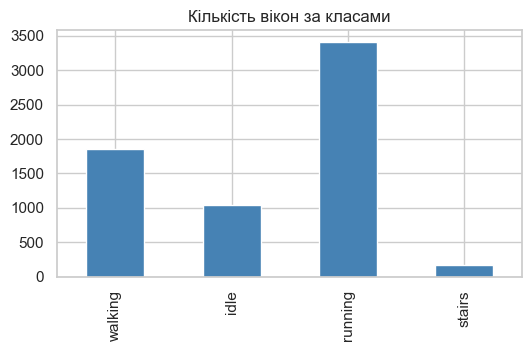

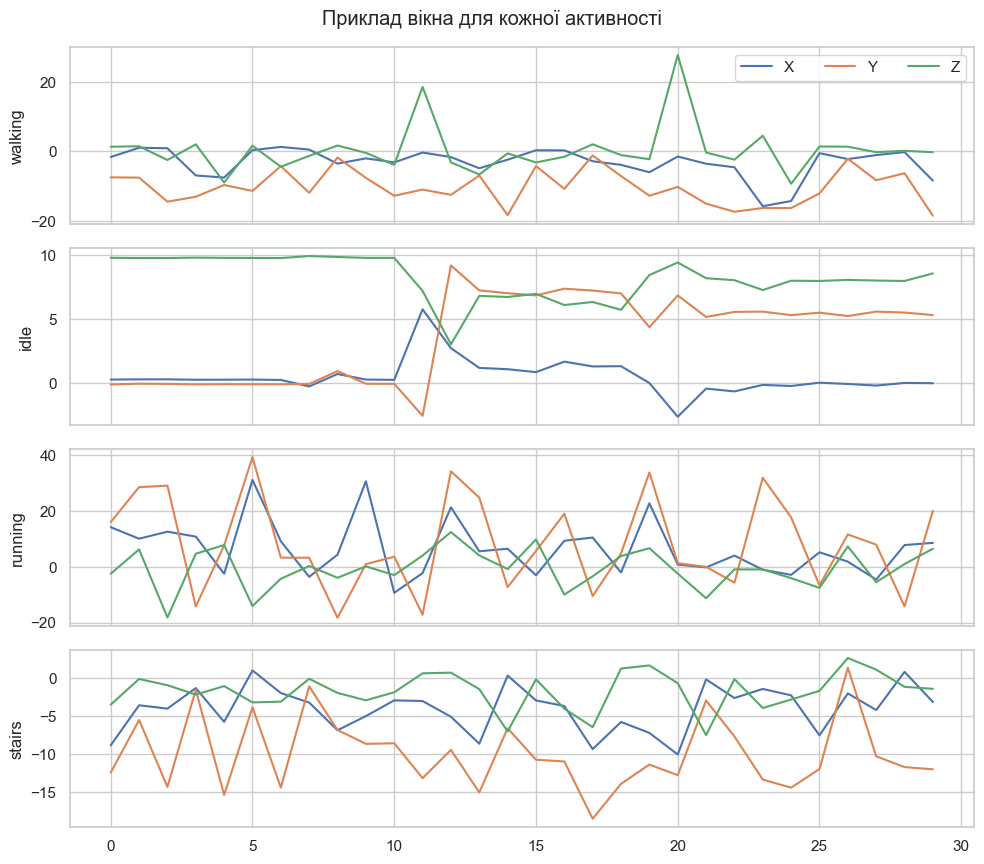

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
counts.plot.bar(ax=ax, color='steelblue')
ax.set_title('Кількість вікон за класами')
plt.show()

rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASS_ORDER), 1, figsize=(10, 2.2*len(CLASS_ORDER)), sharex=True)
for a, cl in zip(axes, CLASS_ORDER):
    rec = [r for r in records if r["label"] == cl]
    a.plot(rec[rng.integers(len(rec))]["signal"])
    a.set_ylabel(cl)
axes[0].legend(['X', 'Y', 'Z'], ncol=3, loc='upper right')
plt.suptitle('Приклад вікна для кожної активності')
plt.tight_layout()
plt.show()

**Спостереження:** клас `stairs` у кілька разів менший за інші, тому accuracy тут оманлива (модель, що ніколи не передбачає `stairs`, все одно матиме високий accuracy). Саме тому порівнюємо моделі за `classification_report`, насамперед recall і F1 по кожному класу та macro-F1. Також використовується стратифікований поділ на train/test.

## 2. Побудова двух наборів ознак

In [4]:
unique_lengths = sorted({len(r["signal"]) for r in records})
if len(unique_lengths) != 1:
    raise ValueError(f"Для сирого представлення потрібна однакова довжина, знайдено: {unique_lengths}")

def time_features(signal):
    out = {}
    for j, axis in enumerate("XYZ"):
        x = signal[:, j]
        out.update({
            f"{axis}_mean": np.mean(x),
            f"{axis}_std": np.std(x),
            f"{axis}_min": np.min(x),
            f"{axis}_max": np.max(x),
            f"{axis}_range": np.ptp(x),
            f"{axis}_median": np.median(x),
            f"{axis}_rms": np.sqrt(np.mean(x**2)),
            f"{axis}_skew": skew(x, bias=False) if np.std(x) > 0 else 0.0,
            f"{axis}_kurtosis": kurtosis(x, fisher=True, bias=False) if np.std(x) > 0 else 0.0,
        })
    magnitude = np.linalg.norm(signal, axis=1)
    out.update({
        "SMA": np.mean(np.abs(signal).sum(axis=1)),
        "magnitude_mean": magnitude.mean(),
        "magnitude_std": magnitude.std(),
        "magnitude_min": magnitude.min(),
        "magnitude_max": magnitude.max(),
        "magnitude_rms": np.sqrt(np.mean(magnitude**2)),
    })
    corr = np.corrcoef(signal, rowvar=False)
    for (i, j), name in zip([(0, 1), (0, 2), (1, 2)], ["XY", "XZ", "YZ"]):
        out[f"corr_{name}"] = 0.0 if not np.isfinite(corr[i, j]) else corr[i, j]
    return out

X_raw = pd.DataFrame([r["signal"].reshape(-1) for r in records])
X_raw.columns = [f"sample_{i}_{axis}" for i in range(len(records[0]["signal"])) for axis in "XYZ"]
X_time = pd.DataFrame([time_features(r["signal"]) for r in records])
y = pd.Series([r["label"] for r in records], name="activity")
print(f"Сирих ознак: {X_raw.shape[1]} | часових ознак: {X_time.shape[1]}")
display(X_time.describe().T.head(12))


Сирих ознак: 90 | часових ознак: 36


,count,mean,std,min,25%,50%,75%,max
X_mean,6462.0,1.923550,4.592754,-7.216762,-2.567462,0.524490,6.094720,13.119427
X_std,6462.0,6.047206,3.603417,0.011577,3.492232,6.072508,9.091413,15.722598
X_min,6462.0,-8.995760,6.921241,-39.188293,-12.169727,-7.264008,-4.788403,0.981623
X_max,6462.0,16.152018,13.680749,-0.541090,2.987964,12.133814,28.452694,39.188293
X_range,6462.0,25.147779,14.387720,0.043096,14.786591,26.575639,36.272155,72.367143
X_median,6462.0,1.336733,3.452385,-5.621586,-1.951275,0.462081,4.378995,10.204087
X_rms,6462.0,7.434691,4.366898,0.091712,4.501822,7.531075,10.953991,19.669309
X_skew,6462.0,0.208089,1.135702,-5.443260,-0.542220,0.440181,0.946524,5.461429
X_kurtosis,6462.0,1.592901,3.443572,-1.350392,-0.111824,0.647268,1.824560,29.882938
Y_mean,6462.0,1.598343,8.036390,-12.616645,-8.847094,5.836106,8.288128,13.322136


## 3. Стратифікований поділ на навчальну й тестову вибірки

In [5]:
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("Train:")
display(y_train.value_counts().reindex(CLASS_ORDER).rename("n").to_frame())
print("Test:")
display(y_test.value_counts().reindex(CLASS_ORDER).rename("n").to_frame())

Train:


,n
activity,
walking,1387
idle,779
running,2556
stairs,124


Test:


,n
activity,
walking,463
idle,260
running,852
stairs,41


## 4. Навчання та classification report

In [6]:
feature_sets = {"Сирі виміри": X_raw, "Часові ознаки": X_time}
models = {
    "SVM (RBF)": lambda: make_pipeline(
        StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample", random_state=RANDOM_STATE,
        n_jobs=-1, min_samples_leaf=2
    ),
}
reports = {}
predictions = {}
for feature_name, X in feature_sets.items():
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    for model_name, build_model in models.items():
        model = build_model()
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        key = (feature_name, model_name)
        predictions[key] = pred
        reports[key] = classification_report(
            y_test, pred, labels=CLASS_ORDER, target_names=CLASS_ORDER,
            output_dict=True, zero_division=0
        )
        print(f"\n{'='*72}\n{feature_name} | {model_name}\n{'='*72}")
        print(classification_report(
            y_test, pred, labels=CLASS_ORDER, target_names=CLASS_ORDER, zero_division=0, digits=3
        ))



Сирі виміри | SVM (RBF)
              precision    recall  f1-score   support

     walking      0.968     0.920     0.944       463
        idle      0.996     1.000     0.998       260
     running      1.000     0.999     0.999       852
      stairs      0.422     0.659     0.514        41

    accuracy                          0.968      1616
   macro avg      0.847     0.894     0.864      1616
weighted avg      0.976     0.968     0.971      1616


Сирі виміри | Random Forest
              precision    recall  f1-score   support

     walking      0.930     1.000     0.964       463
        idle      1.000     1.000     1.000       260
     running      1.000     1.000     1.000       852
      stairs      1.000     0.146     0.255        41

    accuracy                          0.978      1616
   macro avg      0.982     0.787     0.805      1616
weighted avg      0.980     0.978     0.971      1616


Часові ознаки | SVM (RBF)
              precision    recall  f1-score   sup

## 5. Порівняння загальних зведених метрик

In [7]:
summary = []
for (feature_name, model_name), report in reports.items():
    summary.append({
        "Ознаки": feature_name,
        "Модель": model_name,
        "Macro precision": report["macro avg"]["precision"],
        "Macro recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Weighted F1": report["weighted avg"]["f1-score"],
    })
summary_df = pd.DataFrame(summary).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(summary_df.round(3))

,Ознаки,Модель,Macro precision,Macro recall,Macro F1,Weighted F1
0,Часові ознаки,Random Forest,0.988,0.993,0.990,0.998
1,Часові ознаки,SVM (RBF),0.949,0.989,0.967,0.993
2,Сирі виміри,SVM (RBF),0.847,0.894,0.864,0.971
3,Сирі виміри,Random Forest,0.982,0.787,0.805,0.971


## 6. Матриці помилок

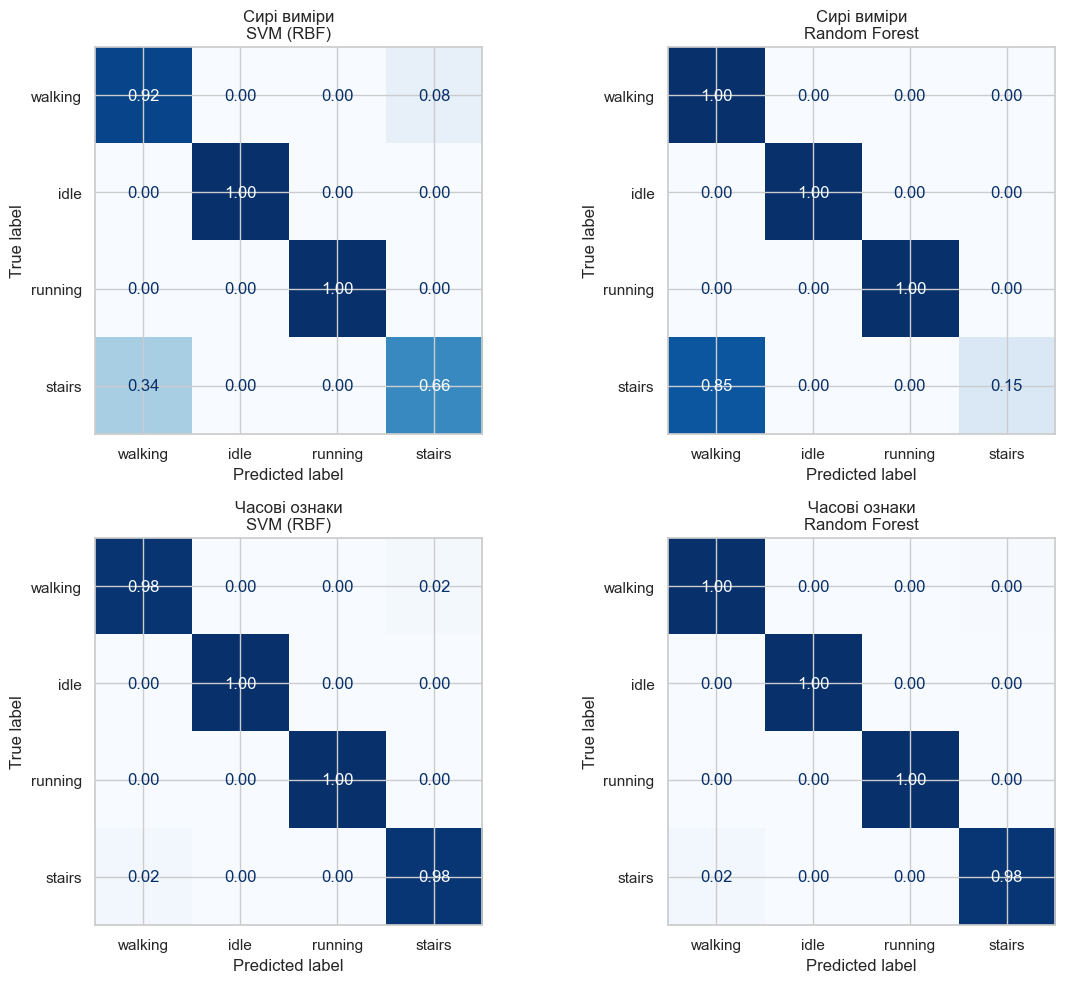

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, ((feature_name, model_name), pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=CLASS_ORDER, display_labels=CLASS_ORDER,
        normalize="true", cmap="Blues", values_format=".2f", ax=ax, colorbar=False
    )
    ax.set_title(f"{feature_name}\n{model_name}")
plt.tight_layout()
plt.show()


## 7. Висновки

Я порівняв SVM (RBF) і Random Forest на двох наборах ознак: сирі виміри акселерометра (90 значень на вікно) та часові ознаки (36: статистики по осях X, Y, Z, модуль вектора, SMA і кореляції між осями). Оцінював за classification_report: macro F1 та recall окремо для кожного класу. Accuracy не була основною метрикою, бо клас stairs дуже малий (165 вікон із 6462).

Вплив ознак. На сирих вимірах accuracy виглядає високою (0.968 у SVM і 0.978 у Random Forest), але macro F1 лише 0.864 і 0.805. Це приховує проблему stairs: у SVM precision 0.42 (багато хибних спрацювань), а Random Forest має precision 1.0, але recall лише 0.146, тобто знаходить менше ніж кожне шосте вікно зі сходами. Часові ознаки різко покращують результат: macro F1 зростає до 0.967 (SVM) і 0.990 (Random Forest), а recall для stairs досягає 0.976 в обох моделях.

Найкращий баланс. Найкращий баланс між чотирма активностями дає Random Forest на часових ознаках: macro F1 0.990, для stairs precision 0.952, recall 0.976, F1 0.964. SVM на тих самих ознаках знаходить сходи так само добре (recall 0.976), але має більше хибних спрацювань (precision 0.800), тому F1 для stairs нижчий (0.879).

Які класи плутаються. За матрицями помилок плутаються переважно walking і stairs, оскільки ці рухи схожі за характером сигналу. Класи idle і running розпізнаються майже ідеально (F1 ≈ 1.0).

Обмеження. Результат отримано на одному випадковому поділі, тому він має випадкову складову, а клас stairs у тесті налічує лише 41 вікно, тож кілька помилок помітно змінюють його метрики. Також можливий витік даних, якщо сусідні вікна з одного запису потрапили і в train, і в test. Для надійнішої оцінки варто повторити експеримент із кількома значеннями random_state або використати групову крос-валідацію за людьми чи сесіями, якщо в даних є їхні ідентифікатори.